In [482]:
using Plots
include("../src/population_model.jl")
include("../parameters/RA_intermidiate.jl")
p_inter = p
include("../parameters/RA_short.jl")
p_short = p
include("../parameters/RA_long.jl")
p_long = p

ComponentVector{Float64}(b0 = 1.0, g = 0.8976275964304349, m̄ = 0.11, m̲ = 0.8031471805599453, r0 = 0.02040344274221344, z = 0.75, b_target = 0.4, b_limit = 0.2, f_target = 0.08218551792854177, T = [0.975 0.5; 0.025 0.5], σ_R = 0.75, μZ = 0.0, μ_P = 33.435598905765794, μ_Ce = 0.0, s̄ = -2.0, k = 0.0, y0 = 0.01, cf = 1.0e-6, cv = 0.0, κ_bankrupt = 0.01, γ = 1.001)

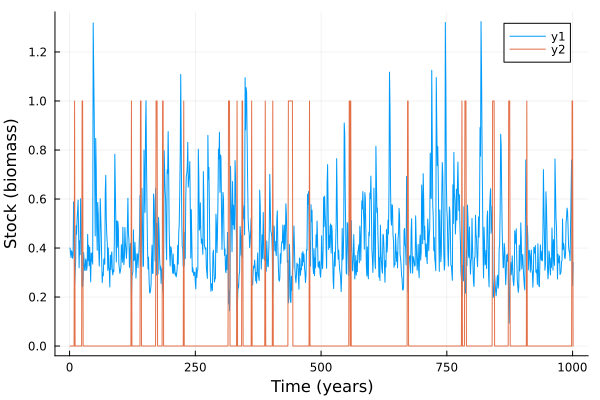

In [485]:
include("../src/model.jl")

function build_sampler(p)
    function sampler()
        return [p.μZ, p.μ_P, p.μ_Ce, rand(Distributions.Normal(0, p.σ_R))]
    end
    return sampler
end

pars = p_short
params_name = "short"
T_ = 1000
utility_ = true
δ_ = 0.95

X2 = MarkovChain(p.T)
sampler_ = build_sampler(pars)
Xmc = MCRandomVariable(sampler_, X2, 1)   
states, m, f, h, y = simulate_trajectory(pars,Xmc,T_)
 
plot(exp.(states[1,:]), xlab = "Time (years)", ylab = "Stock (biomass)")
plot!(states[3,:].-1, xlab = "Time (years)", ylab = "Stock (biomass)")

In [419]:
include("../src/natural_capital.jl")
value_fn, prob, Xmc = solve_natural_capital(pars; δ = δ_, params_name = params_name, 
                                            Nquad = 15, utility_payoff = utility_)

nothing

Progress: 100%|█████████████████████████████████████████| Time: 0:00:27


In [415]:
PV_y, prob, Xmc = solve_natural_capital(pars; δ = δ_, params_name = params_name, 
                                            Nquad = 15, utility_payoff = false)
nothing

Progress: 100%|█████████████████████████████████████████| Time: 0:00:28


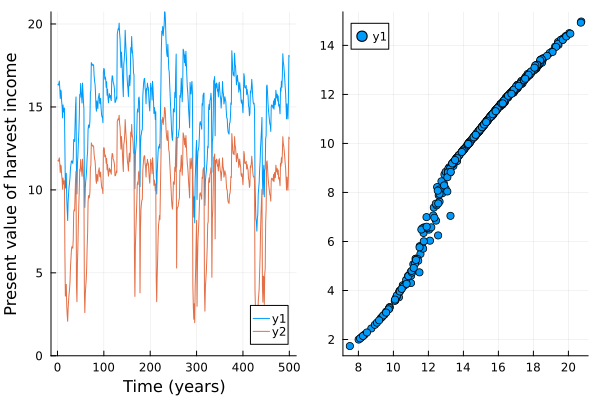

In [416]:
NCAP= broadcast(t -> natural_capital_price(value_fn, states[:,t]),1:T_)
PV_y_ = broadcast(t -> natural_capital_price(PV_y, states[:,t]),1:T_)
W_CE = broadcast(t -> certainty_equivalent_income(NCAP[t], δ_, pars),1:T_)
p1 = plot(PV_y_, ylims = (0,maximum(vcat(W_CE,PV_y_))))
plot!(W_CE, xlab = "Time (years)", ylab = "Present value of harvest income")
p2 = scatter(PV_y_,W_CE)
plot(p1,p2)

In [440]:
sf, Xsf = solve_shortfalls(pars, [0.25,0.5,0.75,1.0])

Progress: 100%|█████████████████████████████████████████| Time: 0:01:57
Progress: 100%|█████████████████████████████████████████| Time: 0:01:29
Progress: 100%|█████████████████████████████████████████| Time: 0:01:29
Progress: 100%|█████████████████████████████████████████| Time: 0:01:29


(Dict{Float64, Any}(0.5 => var"#697#698"{DynamicProgram{Function}}(DynamicProgram{Function}(var"#R#695"{var"#704#705"{Float64}}(var"#704#705"{Float64}(0.5)), var"#F#694"(), (b0 = 1.0, g = 0.7710515858035663, m̄ = 0.4, m̲ = 1.0931471805599453, r0 = 0.15928442980271887, z = 0.75, b_target = 0.4, b_limit = 0.2, f_target = 0.38780092441132785, T = [0.975 0.5; 0.025 0.5], σ_R = 0.75, μZ = 0.0, μ_P = 9.315942614997402, μ_Ce = 0.0, s̄ = -2.0, k = 0.0, y0 = 0.01, cf = 1.0e-6, cv = 0.0, κ_bankrupt = 0.01, γ = 1.001), var"#u#693"(), RandomVariable([0.0 0.0 … 0.0 0.0; 9.315942614997402 9.315942614997402 … 9.315942614997402 9.315942614997402; … ; -9.739413341561667 -9.039763785693363 … 9.039763785693363 9.739413341561667; 0.25 0.25 … 0.9875 0.9875], [5.173037499091387e-38, 4.7217073297920564e-33, 3.428140379462198e-29, 6.030222753805445e-26, 3.997547238957574e-23, 1.2612414035840053e-20, 2.184085908100787e-18, 2.2833491234003164e-16, 1.54191434350271e-14, 7.071144680633195e-13  …  3.53557234031660

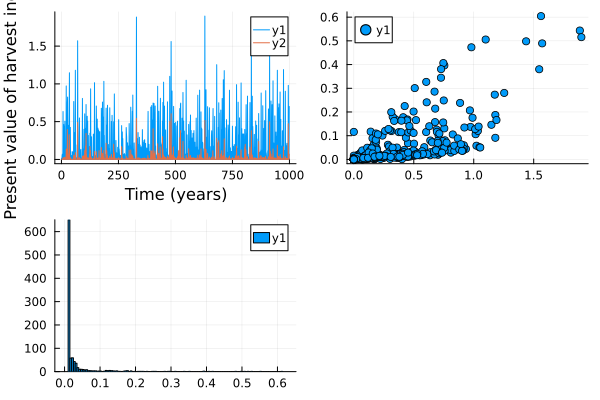

In [448]:
shortfall_05= broadcast(t -> natural_capital_price(sf[0.25], states[:,t]),1:T_)
shortfall_01= broadcast(t -> natural_capital_price(sf[0.75], states[:,t]),1:T_)
change_01 = max.(shortfall_01[1:(T_-1)]-shortfall_01[2:T_],0) 
change_05 = max.(shortfall_05[1:(T_-1)] - shortfall_05[2:T_],0) 
p1 = plot(change_01)
plot!(change_05, xlab = "Time (years)", ylab = "Present value of harvest income")
p2 = scatter(change_01,change_05)
p3 = histogram(change_05.+0.01)
plot(p1,p2,p3)

In [433]:
T

2×2 Matrix{Float64}:
 0.975  0.5
 0.025  0.5

In [486]:
function sample_stock(s0,p,Xmc)
    Xmc()
    ind = sample(1:length(Xmc.weights),Weights(Xmc.weights))
    s1,h,f = update_stock(s0,Xmc.nodes[4:5,ind],p)
    return s1
end 

function delta_NCAP_sample(s0,value_fn,p,Xmc)
    s1 = sample_stock(s0,p,Xmc)
    W0 = natural_capital_price(value_fn, s0)
    W1 = natural_capital_price(value_fn, s1)
    W0_CE = certainty_equivalent_income(W0, δ_, pars)
    W1_CE = certainty_equivalent_income(W1, δ_, pars)
    return W0_CE - W1_CE
end 

s0 = states[:,41]
s1 = sample_stock(s0,pars,Xmc)
W = natural_capital_price(value_fn, s0;)
W_CE = certainty_equivalent_income(W, δ, p)
losses = [delta_NCAP_sample(s0,value_fn,p,Xmc) for i in 1:1000]
Plots.histogram((W_CE .-losses)/W_CE )

LoadError: UndefVarError: `δ` not defined

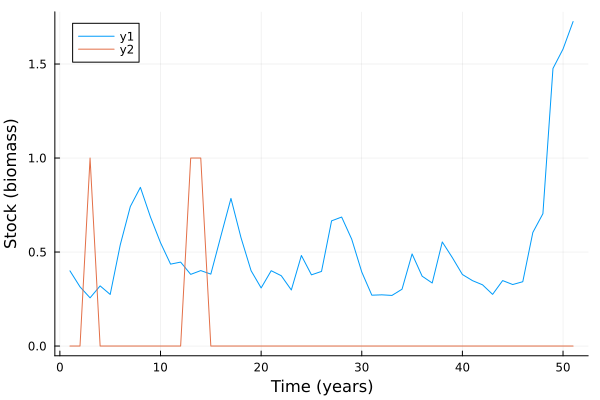

In [ ]:
pars = p_short
params_name = "short"
T_ = 50
utility_ = true
δ_ = 0.95

X2 = MarkovChain(p.T)
sampler_ = build_sampler(pars)
Xmc = MCRandomVariable(sampler_, X2, 1)   
states, m, f, h, y = simulate_trajectory(pars,Xmc,T_)
 
plot(exp.(states[1,:]), xlab = "Time (years)", ylab = "Stock (biomass)")
plot!(states[3,:].-1, xlab = "Time (years)", ylab = "Stock (biomass)")

In [ ]:
s0 = states[:,15]


3-element Vector{Float64}:
 -0.9607568612666237
 -0.04777663777951602
  1.0

# Model of uncertianty loading

The probabiltiy of a transiton each period is uncertain

$p_t \sim Beta(\alpha,\beta)$

At the begining of the period the true probabiltiy $p_t$ is sampled but cannot be directly observed, but each party recieves some informaiton about the true state before they lock in their decisions

$n_{i,t} \sim Binom(N_i,p_t)$

where $i$ indexes over individuals. I assume for not that there is only one representative inurer and insured party $i \in \left\{ \text{insured}, \text{insurer}\right\}$. The beliefs of the two parties may differ after they recieve this information depending on their specieis sample. 

$p_{i,t} \sim Beta(\alpha+n_{i,t},\beta+(N_i-n_{i,t}))$

The parties have asymetric information if one of them has a more informative sample $N_i > N_j$. However, only independent information is required for uncertianty loadings to emerge. Independent informaiton about the sotck is of course quite likely in fisheries. Insurers will have more resources to analyze historical data and oceanographic conditions, while fishermen have direct on the water infomation about the stock. Which of these two sources provides more accurate information is debatable and likely context dependent, however it is nearly certian that both parties wil have some information that is unique to themselves.  


We assume that the demand for insurance is represented by one representative vessel owner, which has CRRA utility over harvest income new of premium costs. They choose a guaranteed minimum revenue from the fishery $\bar{y}_t$ that determines the coverage level based on their precieved risk and the insurers prices.

We assume the insurer is in a competative market or regulated so that their price for insurance equals with expected losses plus a small multiple for capital costs $\lambda$, "the fair premium".

The insurers profit is a function of the realized probability of a loss, the premiums they change and demand for insurance 

We'll model demand for insurance assuming a population of vessel owners with differnt risk aversions $\gamma_i \sim N(\mu_{\gamma},\sigma_{\gamma})$  and estimates of the true probabiltiy $n_{i,t}$.


$\pi(r) = \int_0^{\infty} \left[\sum_{n=0}^{N}(r-q_n) C(n,\gamma;r)\right] BB(n;N,\alpha+ n_I \beta+N_I-n_I)f(\gamma)d\gamma$

In [ ]:
using Plots
include("../src/population_model.jl")
include("../parameters/RA_intermidiate.jl")
p_inter = p
include("../parameters/RA_short.jl")
p_short = p
include("../parameters/RA_long.jl")
p_long = p

ComponentVector{Float64}(b0 = 1.0, g = 0.8976275964304349, m̄ = 0.11, m̲ = 0.8031471805599453, r0 = 0.02040344274221344, z = 0.75, b_target = 0.4, b_limit = 0.2, f_target = 0.08218551792854177, T = [0.975 0.5; 0.025 0.5], σ_R = 0.75, μZ = 0.0, μ_P = 33.435598905765794, μ_Ce = 0.0, s̄ = -2.0, k = 0.0, y0 = 0.01, cf = 1.0e-6, cv = 0.0, κ_bankrupt = 0.01, γ = 1.001)

[-1.0052600115431363, -0.26773459962172963, 1.0]

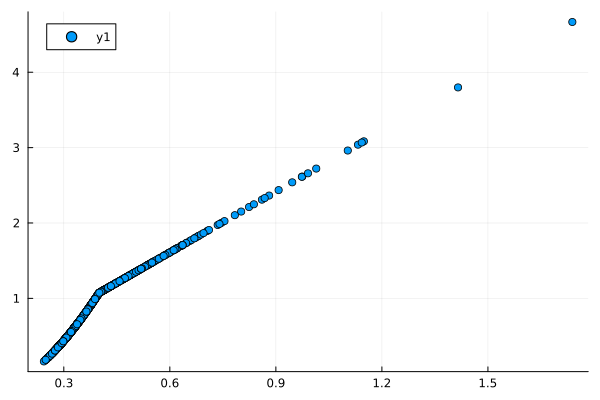

In [ ]:

function sample_harvest(s0, pars, X, I)
    X()
    s1, ht, ft = update_stock(s0,X.nodes[4:5,1],pars,I)
    X()
    # draw the year-2 mortality transition from the chain's nodes by their weights;
    # column 1 alone would fix the Markov draw and make mortality deterministic
    ind = sample(1:length(X.weights),Weights(X.weights))
    s2, h2, ft = update_stock(s1,X.nodes[4:5,ind],pars)
    return 10*h2, exp(s1[1])
end 
print(s0)
h = [sample_harvest(s0, pars, Xmc, 0) for _ in 1:1000]
histogram(h)

In [ ]:
using Statistics, Optim

function utility(c,γ,c0)
    if γ == 1 return log(c + c0) end
    ((c+c0)^(1-γ)-1)/(1-γ)
end 

# Draw once, reuse everywhere
draw_incomes(I, M) = [sample_harvest(s0, pars, Xmc, I) for _ in 1:M]
y0 = draw_incomes(0, 10_000)
y1 = draw_incomes(1, 10_000)

# Expected indemnity in each state for a guaranteed-income floor D
state_means(D, y0, y1) = (mean(max.(D .- y0, 0.0)), mean(max.(D .- y1, 0.0)))

function premium(D, p_r, λ, y0, y1)
    μ0, μ1 = state_means(D, y0, y1)
    return (1 + λ) * (μ0 + p_r * (μ1 - μ0))
end

function expected_utility(D, m_F, p_r, λ, γ, c0, y0, y1)
    P   = premium(D, p_r, λ, y0, y1)
    EU0 = mean(utility.(max.(y0, D) .- P,  γ, c0))
    EU1 = mean(utility.(max.(y1, D) .- P,  γ, c0))
    return (1 - m_F) * EU0 + m_F * EU1
end

function optimal_D(m_F, p_r, λ, γ, c0, y0, y1; Dmax = maximum(y0))
    res = optimize(D -> -expected_utility(D, m_F, p_r, λ, γ, c0, y0, y1), 0.0, Dmax)
    return Optim.minimizer(res)
end



optimal_D (generic function with 2 methods)

In [ ]:

using Distributions, Statistics

"""
Insurer's expected profit per farmer at rating probability p_r,
given the insurer saw n_I losses in N_I trials, with a common γ.
"""
function expected_loss_ratio(p_r, n_I, N_I; α, β, N, λ, γ,c0, y0, y1, optimal_D)

    a, b = α + n_I, β + N_I - n_I            # insurer's posterior parameters
    bb   = BetaBinomial(N, a, b)

    profit = 0.0; premiums=0; losses=0; deductable = 0
    for n in 0:N
        q_n = (a + n) / (a + b + N)          # insurer's pooled posterior mean
        m_F = (α + n) / (α + β + N)          # farmer's own posterior mean

        D  = optimal_D(m_F, p_r, λ, γ,c0, y0, y1; Dmax = maximum(vcat(y0, y1)))

        μ0 = mean(max.(D .- y0, 0.0))
        μ1 = mean(max.(D .- y1, 0.0))
        Δ  = μ1 - μ0
        P  = (1 + λ) * (μ0 + p_r * Δ)

        profit += pdf(bb, n) * (P - μ0 - q_n * Δ)
        premiums += pdf(bb, n) * P
        losses +=  pdf(bb, n) * (μ0 + q_n * Δ)
        # deductable +=  pdf(bb, n) * D
    end
    return losses/premiums 
end


expected_loss_ratio

In [ ]:
using Roots

"Expected premiums and losses per farmer at rating probability p_r."
function premiums_and_losses(p_r, n_I, N_I; α, β, N, λ, γ, c0, y0, y1, optimal_D)
    a, b = α + n_I, β + N_I - n_I            # insurer's posterior parameters
    bb   = BetaBinomial(N, a, b)
    Dmax = maximum(vcat(y0, y1))

    premiums = 0.0
    losses   = 0.0
    for n in 0:N
        q_n = (a + n) / (a + b + N)          # insurer's pooled posterior mean
        m_F = (α + n) / (α + β + N)          # farmer's own posterior mean

        D  = optimal_D(m_F, p_r, λ, γ, c0, y0, y1; Dmax)
        μ0 = mean(max.(D .- y0, 0.0))
        μ1 = mean(max.(D .- y1, 0.0))
        Δ  = μ1 - μ0
        P  = (1 + λ) * (μ0 + p_r * Δ)

        w = pdf(bb, n)
        premiums += w * P
        losses   += w * (μ0 + q_n * Δ)
    end
    return premiums, losses
end

"""
Find p_r such that expected losses / premiums = 1/(1+λ).

Scans upward from the insurer's posterior mean, because the loss ratio is
at or above target there (selection can only make the pool riskier), then
bisects on the first crossing. Returns NaN if the market closes, meaning
demand vanishes, before the target is reached.
"""
function solve_p_r(n_I, N_I; α, β, λ, ngrid = 25, p_hi = nothing, xatol = 1e-5, kw...)
    target = 1 / (1 + λ)
    m_I    = (α + n_I) / (α + β + N_I)
    p_hi   = something(p_hi, min(0.99, 5m_I + 0.05))

    function gap(p_r)
        prem, loss = premiums_and_losses(p_r, n_I, N_I; α, β, λ, kw...)
        return prem > 0 ? loss / prem - target : NaN
    end

    grid = range(m_I, p_hi; length = ngrid)
    g0   = gap(grid[1])
    isnan(g0) && return (; p_r = NaN, reason = "no demand at insurer's mean")
    abs(g0) < 1e-10 && return (; p_r = grid[1], reason = "no selection")

    g_prev = g0
    for k in 2:ngrid
        g = gap(grid[k])
        isnan(g) && return (; p_r = NaN, reason = "market closes before target")
        if g_prev > 0 && g <= 0
            p = find_zero(gap, (grid[k-1], grid[k]), Bisection(); xatol)
            return (; p_r = p, reason = "solved")
        end
        g_prev = g
    end
    return (; p_r = NaN, reason = "no crossing below p_hi; raise p_hi")
end


solve_p_r

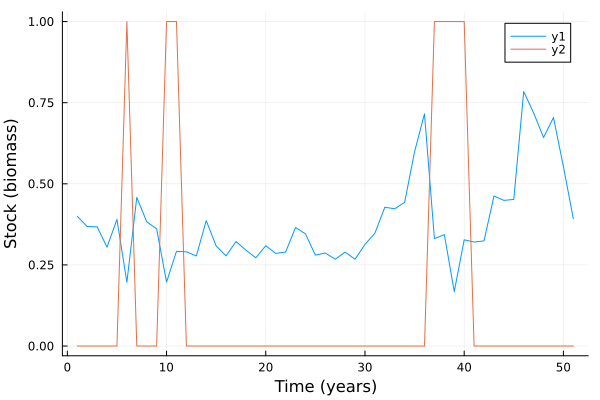

In [ ]:
pars = p_short
params_name = "intermediate"
T_ = 50
utility_ = true
δ_ = 0.95

X2 = MarkovChain(p.T)
sampler_ = build_sampler(pars)
Xmc = MCRandomVariable(sampler_, X2, 1)   
states, m, f, h, y = simulate_trajectory(pars,Xmc,T_)
s0 = states[:,20]
plot(exp.(states[1,:]), xlab = "Time (years)", ylab = "Stock (biomass)")
plot!(states[3,:].-1, xlab = "Time (years)", ylab = "Stock (biomass)")

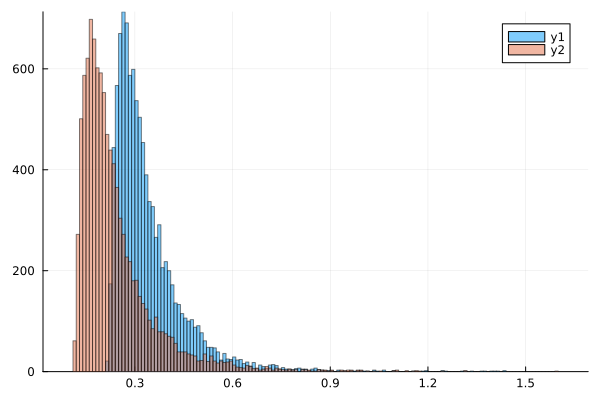

In [ ]:
# Draw once, reuse everywhere
s0 = states[:,25]
draw_incomes(I, M) = [sample_harvest(s0, pars, Xmc, I) for _ in 1:M]
y0 = draw_incomes(0, 10_000)
y1 = draw_incomes(1, 10_000)
histogram(y0, alpha = 0.5)
histogram!(y1, alpha = 0.5)

In [ ]:
α = 20*pars.T[2,1]
β = 20*(1-pars.T[2,1])
λ = 0.025
c0 = 0.005*mean(y0)
γ = 1.0
n_I = 1
N_I = 2
p_r = (α + n_I) / (α + β + N_I)
N = 4
p_r_star, sol = solve_p_r(n_I, N_I; α, β, λ, N, γ, c0, y0, y1,optimal_D)
println(p_r)
println(p_r_star)
println(p_r_star - p_r)
print((p_r_star - p_r)/p_r)

LoadError: MethodError: no method matching /(::Tuple{Float64, Float64}, ::Int64)

[0mClosest candidates are:
[0m  /([91m::BigInt[39m, ::Union{Int16, Int32, Int64, Int8, UInt16, UInt32, UInt64, UInt8})
[0m[90m   @[39m [90mBase[39m [90m[4mgmp.jl:565[24m[39m
[0m  /([91m::BigFloat[39m, ::Union{Int16, Int32, Int64, Int8})
[0m[90m   @[39m [90mBase[39m [90m[4mmpfr.jl:494[24m[39m
[0m  /([91m::Missing[39m, ::Number)
[0m[90m   @[39m [90mBase[39m [90m[4mmissing.jl:123[24m[39m
[0m  ...


In [ ]:
# Uncertainty loading with parametic 

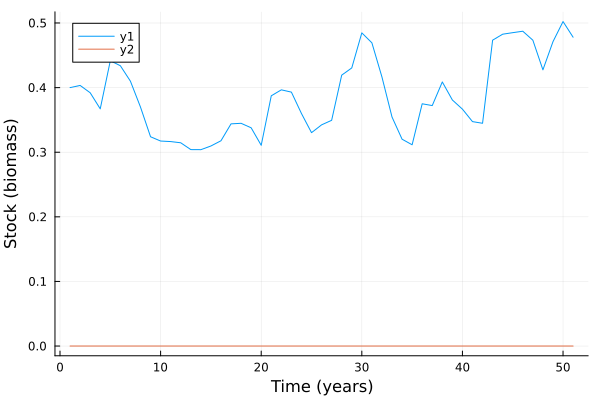

In [509]:
pars = p_inter
params_name = "intermediate"
T_ = 50
utility_ = true
δ_ = 0.95

X2 = MarkovChain(p.T)
sampler_ = build_sampler(pars)
Xmc = MCRandomVariable(sampler_, X2, 1)   
states, m, f, h, y = simulate_trajectory(pars,Xmc,T_)
s0 = states[:,20]
plot(exp.(states[1,:]), xlab = "Time (years)", ylab = "Stock (biomass)")
plot!(states[3,:].-1, xlab = "Time (years)", ylab = "Stock (biomass)")

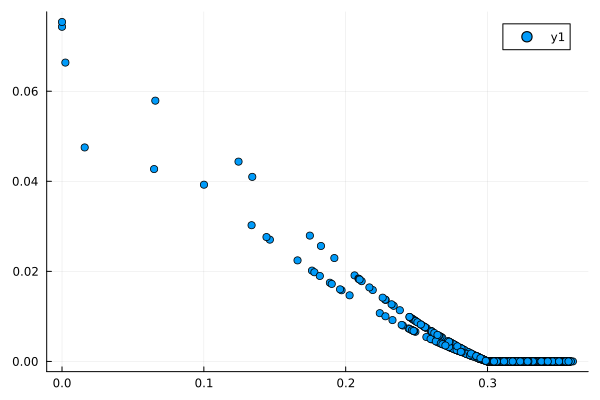

In [510]:
function sample_harvest(s0, pars, X, I, strike)
    X()
    s1, ht, ft = update_stock(s0,X.nodes[4:5,1],pars,I)
    X()
    # draw the year-2 mortality transition from the chain's nodes by their weights;
    # column 1 alone would fix the Markov draw and make mortality deterministic
    ind = sample(1:length(X.weights),Weights(X.weights))
    s2, h2, ft = update_stock(s1,X.nodes[4:5,ind],pars)
    return h2, max.(strike.-exp(s1[1]),0)
end 

samples = [sample_harvest(s0, pars, Xmc, 1, 0.5) for _ in 1:1000]
h = [samples[i][1] for i in 1:1000]
b  = [samples[i][2] for i in 1:1000]
scatter(b, h)

In [511]:
# Draw once, reuse everywhere
strike_ = 0.3
draw_samples(I, M) = [sample_harvest(s0, pars, Xmc, I,strike_) for _ in 1:M]
samples_0 = [sample_harvest(s0, pars, Xmc, 0, strike_) for _ in 1:1000]
samples_1 = [sample_harvest(s0, pars, Xmc, 1, strike_) for _ in 1:1000]
y0 = [samples_0[i][1] for i in 1:1000]
y1 = [samples_1[i][1] for i in 1:1000]
I0 = [samples_0[i][2] for i in 1:1000]
I1 = [samples_1[i][2] for i in 1:1000]
EL0 = mean(I0)
EL1 = mean(I1)

# The contract pays ϕ × (index shortfall), so expected losses and premiums scale linearly in ϕ.
function premium_ϕ(ϕ, p_r, λ, EL0, EL1)
    μ0, μ1 = ϕ*EL0, ϕ*EL1
    return (1 + λ) * (μ0 + p_r * (μ1 - μ0))
end

# Expected utility of harvest income plus the indemnity ϕ*I, net of the premium.
# m_F is the farmer's belief that the loss-event state (I = 1) occurs.
function expected_utility_ϕ(ϕ, m_F, p_r, λ, γ, c0, I0, I1, EL0, EL1, y0, y1)
    P   = premium_ϕ(ϕ, p_r, λ, EL0, EL1)
    EU0 = mean(utility.(y0 .+ ϕ .* I0 .- P,  γ, c0))
    EU1 = mean(utility.(y1 .+ ϕ .* I1 .- P,  γ, c0))
    return (1 - m_F) * EU0 + m_F * EU1
end

# Upper bound on coverage ϕ: the hedge slope, the regression slope of income loss on the
# unscaled index shortfall, -Cov(y, I)/Var(I). Beyond it extra coverage adds basis risk
# (the insurer would be selling a lottery ticket beyond what the insured could lose).
# The two states are weighted by m_I, the insurer's posterior probability of the event
# state, as the contract's own risk measure can't depend on the unobserved true probability.
# Floored at 1e-8 if the index never pays or is positively correlated with income.
function hedge_ϕ(y0, y1, I0, I1, m_I)
    w0, w1 = 1 - m_I, m_I
    ȳ  = w0 * mean(y0) + w1 * mean(y1)
    Ī  = w0 * mean(I0) + w1 * mean(I1)
    cov_yI = w0 * mean((y0 .- ȳ) .* (I0 .- Ī)) + w1 * mean((y1 .- ȳ) .* (I1 .- Ī))
    var_I  = w0 * mean((I0 .- Ī).^2) + w1 * mean((I1 .- Ī).^2)
    var_I > 0 || return 1e-8
    return max(-cov_yI / var_I, 1e-8)
end

# ϕmax is required; use hedge_ϕ(y0, y1, I0, I1, m_I) with the insurer's mean m_I.
function optimal_ϕ(m_F, p_r, λ, γ, c0, I0, I1, EL0, EL1, y0, y1; ϕmax)
    res = optimize(ϕ -> -expected_utility_ϕ(ϕ, m_F, p_r, λ, γ, c0, I0, I1, EL0, EL1, y0, y1), 0.0, ϕmax)
    return Optim.minimizer(res)
end


optimal_ϕ (generic function with 1 method)

In [512]:
m_F
p_r

0.06818181818181818

In [513]:
optimal_ϕ(m_F, p_r, λ, γ, c0, I0, I1, EL0, EL1, y0, y1; ϕmax = hedge_ϕ(y0, y1, I0, I1, (α + n_I) / (α + β + N_I)))

0.23129952299832265

In [514]:
using Roots

"Expected premiums and losses per farmer at rating probability p_r, for the proportional index contract."
function premiums_and_losses_ϕ(p_r, n_I, N_I; α, β, N, λ, γ, c0, y0, y1, I0, I1, EL0, EL1,
                               ϕmax = hedge_ϕ(y0, y1, I0, I1, (α + n_I) / (α + β + N_I)))
    a, b = α + n_I, β + N_I - n_I            # insurer's posterior parameters
    bb   = BetaBinomial(N, a, b)

    premiums = 0.0
    losses   = 0.0
    for n in 0:N
        q_n = (a + n) / (a + b + N)          # insurer's pooled posterior mean
        m_F = (α + n) / (α + β + N)          # farmer's own posterior mean

        ϕ  = optimal_ϕ(m_F, p_r, λ, γ, c0, I0, I1, EL0, EL1, y0, y1; ϕmax)
        μ0 = ϕ * EL0                         # expected indemnity, no-event state
        μ1 = ϕ * EL1                         # expected indemnity, event state
        Δ  = μ1 - μ0
        P  = (1 + λ) * (μ0 + p_r * Δ)

        w = pdf(bb, n)
        premiums += w * P
        losses   += w * (μ0 + q_n * Δ)
    end
    return premiums, losses
end

"""
Find p_r such that expected losses / premiums = 1/(1+λ) for the proportional index contract.

Scans upward from the insurer's posterior mean, because the loss ratio is
at or above target there (selection can only make the pool riskier), then
bisects on the first crossing. Returns NaN if the market closes, meaning
demand vanishes, before the target is reached.
Required keywords forwarded to premiums_and_losses_ϕ: N, γ, c0, y0, y1, I0, I1, EL0, EL1 (and optionally ϕmax, which defaults to the hedge slope weighted by the insurer's mean).
"""
function solve_p_r_ϕ(n_I, N_I; α, β, λ, ngrid = 25, p_hi = nothing, xatol = 1e-5, kw...)
    target = 1 / (1 + λ)
    m_I    = (α + n_I) / (α + β + N_I)
    p_hi   = something(p_hi, min(0.99, 5m_I + 0.05))

    function gap(p_r)
        prem, loss = premiums_and_losses_ϕ(p_r, n_I, N_I; α, β, λ, kw...)
        return prem > 0 ? loss / prem - target : NaN
    end

    grid = range(m_I, p_hi; length = ngrid)
    g0   = gap(grid[1])
    isnan(g0) && return (; p_r = NaN, reason = "no demand at insurer's mean")
    abs(g0) < 1e-10 && return (; p_r = grid[1], reason = "no selection")

    g_prev = g0
    for k in 2:ngrid
        g = gap(grid[k])
        isnan(g) && return (; p_r = NaN, reason = "market closes before target")
        if g_prev > 0 && g <= 0
            p = find_zero(gap, (grid[k-1], grid[k]), Bisection(); xatol)
            return (; p_r = p, reason = "solved")
        end
        g_prev = g
    end
    return (; p_r = NaN, reason = "no crossing below p_hi; raise p_hi")
end


solve_p_r_ϕ

In [515]:
# Solve for the equilibrium rating probability p_r* of the proportional index contract:
# the p_r at which expected losses / premiums = 1/(1+λ), given the insurer's signal (n_I of N_I).
α   = 20*pars.T[2,1]            # Beta(α, β) prior on the event probability
β   = 20*(1-pars.T[2,1])
λ   = 0.0                    # loading for capital costs
γ   = 1.0                       # CRRA risk aversion
c0  = 0.005*mean(y0)            # consumption offset in utility
n_I, N_I = 1, 2                 # insurer's signal: n_I events in N_I trials
N   = 2                         # trials in the farmer's signal
m_I = (α + n_I) / (α + β + N_I) # insurer's posterior mean (the rate with no selection)

sol = solve_p_r_ϕ(n_I, N_I; α, β, λ, N, γ, c0, y0, y1, I0, I1, EL0, EL1)

println("reason:        ", sol.reason)
println("insurer mean:  ", m_I)
println("p_r*:          ", sol.p_r)
println("difference:    ", sol.p_r - m_I)
println("relative load: ", (sol.p_r - m_I)/m_I)

# coverage chosen at the equilibrium rate for each possible farmer signal n;
# flags coverage that sits at the search bound ϕmax (the bound would then drive the result)
if !isnan(sol.p_r)
    ϕmax = hedge_ϕ(y0, y1, I0, I1, m_I)
    println("ϕmax (hedge slope at insurer's mean): ", round(ϕmax, digits = 3))
    for n in 0:N
        m_F = (α + n) / (α + β + N)
        ϕ   = optimal_ϕ(m_F, sol.p_r, λ, γ, c0, I0, I1, EL0, EL1, y0, y1; ϕmax)
        println("n = $n   m_F = $(round(m_F, digits = 3))   ϕ* = $(round(ϕ, digits = 3))",
                ϕ > 0.999ϕmax ? "   (at ϕmax)" : "")
    end
end

reason:        solved
insurer mean:  0.06818181818181818
p_r*:          0.07655991062973483
difference:    0.008378092447916652
relative load: 0.12287868923611091
ϕmax (hedge slope at insurer's mean): 0.231
n = 0   m_F = 0.023   ϕ* = 0.061
n = 1   m_F = 0.068   ϕ* = 0.189
n = 2   m_F = 0.114   ϕ* = 0.231   (at ϕmax)
